<a href="https://colab.research.google.com/github/luisavgonzalez27/ads-509-Final-Project/blob/main/02_MAUDE_Text_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAUDE Medical Device Adverse Event Data Collection

## Notebook 02 - MAUDE_Text_Classification

Uses FDA MAUDE narratives to classify Malfunction, Injury, or Death, using text embeddings.

* Examines narrative length and top bigrams by event type.
* Splits data into 80% training and 20% testing using stratified sampling.
* Converts narratives into numerical representations using a pretrained Sentence-BERT model.
* Trains and evaluates a multiclass logistic regression model using the Sentence-BERT embeddings.
* Compares the results with a weighted balanced logistic regression model.
* Misclassified reports are examined individually to better understand where the model has difficulty distinguishing between event types.

## Key Findings

- The standard Sentence-BERT + Logistic Regression achieved 96.5% accuracy and a 0.9518 macro F1-score on the 200-report test set.

- The standard model achieved F1-scores of 0.9804 for Malfunction, 0.9560 for Injury, and 0.9189 for Death.

- The balanced Sentence-BERT + Logistic Regression model achieved 94.0% accuracy and a 0.9309 macro F1-score.

- Class weighting increased Death recall from 85% to 100%. The balanced model correctly identified all 20 Death reports, compared with 17 of 20 for the standard model. But resulted in decrease in Death precision from 100% to 83.3%.

- Error analysis identified potential inconsistencies between the narrative text and reported event type. Some narratives did not contain information supporting their assigned event type. These inconsistencies may reflect human labeling errors or incomplete narrative information. This highlights a need for model-driven classification pipeline.

- Other errors represented clear model misclassifications.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score)
from sklearn.feature_extraction.text import (CountVectorizer,ENGLISH_STOP_WORDS)


In [2]:
#load data
df = pd.read_csv("fda_cgm_reports_1000.csv")

print(df.shape)
print(df["event_type"].value_counts())
df.head(2)

(1000, 10)
event_type
Malfunction    500
Injury         400
Death          100
Name: count, dtype: int64


,report_id,date_received,brand_name,generic_name,manufacturer,product_code,narrative,event_type,product_problems,patient_problems
0,3004753838-2020-038805,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT EARLY SENSOR EXPIRATION O...,Malfunction,"['Premature End-of-Life Indicator', 'Premature...","['No Consequences Or Impact To Patient', 'No C..."
1,3004753838-2020-038806,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT SIGNAL LOSS OVER ONE HOUR...,Malfunction,"['Wireless Communication Problem', 'Wireless C...","['No Consequences Or Impact To Patient', 'No C..."
2,3004753838-2020-038807,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT SIGNAL LOSS OVER ONE HOUR...,Malfunction,"['Wireless Communication Problem', 'Wireless C...","['No Consequences Or Impact To Patient', 'No C..."
3,3004753838-2020-038809,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT SIGNAL LOSS OVER ONE HOUR...,Malfunction,"['Wireless Communication Problem', 'Wireless C...","['No Consequences Or Impact To Patient', 'No C..."
4,3004753838-2020-038810,20200427,DEXCOM G6 CONTINUOUS GLUCOSE MONITORING SYSTEM,CONTINUOUS GLUCOSE MONITOR,"DEXCOM, INC.",QBJ,IT WAS REPORTED THAT EARLY SENSOR EXPIRATION O...,Malfunction,"['Premature End-of-Life Indicator', 'Premature...","['No Consequences Or Impact To Patient', 'No C..."


Examine narrative length by event type

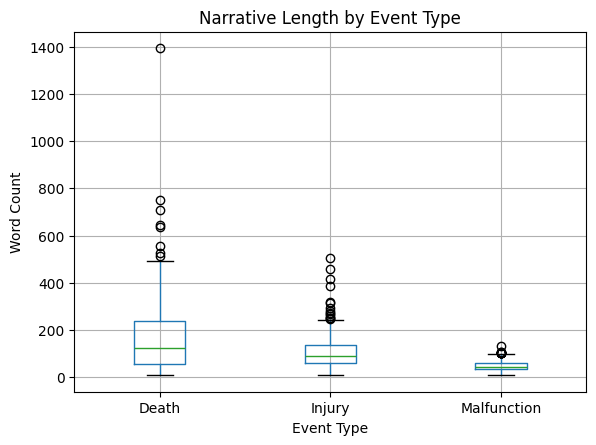

In [28]:
#plot narrative length by event type
df["word_count"] = df["narrative"].fillna("").str.split().str.len()
df["character_count"] = df["narrative"].fillna("").str.len()

df.boxplot(column="word_count", by="event_type")

plt.title("Narrative Length by Event Type")
plt.suptitle("")
plt.xlabel("Event Type")
plt.ylabel("Word Count")
plt.show()

Examine the top bigrams by event type

In [30]:
# remove filler words
custom_stop_words = list(
    ENGLISH_STOP_WORDS.union({
        "reported",
        "information",
        "available",
        "additional",
        "event",
        "provided",
        "occurred"}))

def get_top_bigrams(data, event_type, n=15):

    texts = data.loc[
        data["event_type"] == event_type,
        "narrative"
    ].dropna()

    vectorizer = CountVectorizer(
        stop_words=custom_stop_words,
        ngram_range=(2, 2),
        max_features=2000,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
    )

    X = vectorizer.fit_transform(texts)

    counts = X.sum(axis=0).A1
    bigrams = vectorizer.get_feature_names_out()

    frequencies = pd.DataFrame({
        "bigram": bigrams,
        "count": counts})

    return frequencies.sort_values(
        "count",
        ascending=False).head(n)

In [26]:
for event in ["Malfunction", "Injury", "Death"]:
    print(f"\nTop bigrams: {event}")
    display(get_top_bigrams(df, event))


Top bigrams: Malfunction


,bigram,count
82,cause determined,423
497,probable cause,376
414,medical intervention,370
347,injury medical,370
189,determined injury,275
616,signal loss,239
25,allegation confirmed,187
119,confirmed probable,182
399,loss hour,166
112,confirmation allegation,156



Top bigrams: Injury


,bigram,count
1174,mg dl,307
1625,sensor inserted,199
189,blood glucose,181
1700,skin reaction,178
245,cause determined,168
336,continuous glucose,138
993,inserted abdomen,137
865,glucose bg,136
876,glucose monitor,134
1406,probable cause,126



Top bigrams: Death


,bigram,count
1533,mg dl,156
1590,passed away,64
1626,patient passed,51
1499,low alert,42
1939,urgent low,42
979,egv mg,36
1827,sensor session,33
1611,patient egvs,31
1690,probable cause,28
30,adc device,28


Modeling Phase

In [3]:
#drop unnecessary variables to avoid leakage
model_df = df[["narrative", "event_type"]].copy()

model_df = model_df.dropna(subset=["narrative", "event_type"])

print(model_df.shape)
print(model_df["event_type"].value_counts())

(1000, 2)
event_type
Malfunction    500
Injury         400
Death          100
Name: count, dtype: int64


In [38]:
#Split the data into training and test set, using stratified sampling
X_train_text, X_test_text, y_train, y_test = train_test_split(
    model_df["narrative"],
    model_df["event_type"],
    test_size=0.20,
    random_state=20,
    stratify=model_df["event_type"])

print("Training observations:", len(X_train_text))
print("Testing observations:", len(X_test_text))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

#Save training and test datasets
train_df = pd.DataFrame({"narrative": X_train_text, "event_type": y_train}).reset_index(drop=True)

test_df = pd.DataFrame({"narrative": X_test_text, "event_type": y_test}).reset_index(drop=True)

train_df.to_csv("fda_cgm_train.csv", index=False)
test_df.to_csv("fda_cgm_test.csv", index=False)

Training observations: 800
Testing observations: 200

Training distribution:
event_type
Malfunction    400
Injury         320
Death           80
Name: count, dtype: int64

Testing distribution:
event_type
Malfunction    100
Injury          80
Death           20
Name: count, dtype: int64


In [32]:
#Turn medical narratives into embeddings
encoder = SentenceTransformer("all-MiniLM-L6-v2")

X_train_embeddings = encoder.encode(
    X_train_text.tolist(),
    batch_size=32,
    show_progress_bar=True)

X_test_embeddings = encoder.encode(
    X_test_text.tolist(),
    batch_size=32,
    show_progress_bar=True)

print(X_train_embeddings.shape)
print(X_test_embeddings.shape)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

(800, 384)
(200, 384)


Model 1 - Logistic Regression

In [33]:
# Use embeddings in a logistic regression model
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_embeddings, y_train)

y_pred = lr.predict(X_test_embeddings)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred,
        labels=["Malfunction", "Injury", "Death"]))

Accuracy: 0.965
Macro F1: 0.9518

Classification Report:
              precision    recall  f1-score   support

       Death     1.0000    0.8500    0.9189        20
      Injury     0.9620    0.9500    0.9560        80
 Malfunction     0.9615    1.0000    0.9804       100

    accuracy                         0.9650       200
   macro avg     0.9745    0.9333    0.9518       200
weighted avg     0.9656    0.9650    0.9645       200


Confusion Matrix:
[[100   0   0]
 [  4  76   0]
 [  0   3  17]]


In [34]:
#Examine reports that were incorrectly classifed
pd.set_option("display.max_colwidth", None)

results = pd.DataFrame({
    "narrative": X_test_text.values,
    "actual": y_test.values,
    "predicted": y_pred})

errors = results[results["actual"] != results["predicted"]]
errors

,narrative,actual,predicted
29,"SUBSEQUENT TO THE INITIAL MDR, IT WAS DETERMINED THAT A REPORT WAS SUBMITTED IN ERROR. UPON FURTHER REVIEW, IT WAS DETERMINED THAT THE PATIENT ALLEGATION DOES NOT MEET THE CRITERIA OF A REPORTABLE EVENT.",Injury,Malfunction
31,"A LOW READINGS ISSUE WITH THE ADC DEVICE WAS REPORTED. THE CUSTOMER RECEIVED UNSPECIFIED LOW SENSOR READINGS AND AS A RESULT THE CUSTOMER EXPERIENCED LOSS OF CONSCIOUSNESS AND HEAVY SWEATING. THE CUSTOMER WAS UNABLE TO SELF TREAT AND RECEIVED UNSPECIFIED TREATMENT FROM A HEALTHCARE PROFESSIONAL (HCP). NO FURTHER TREATMENT DETAILS WERE REPORTED. ADDITIONALLY, IT WAS REPORTED THE CUSTOMER RECEIVED SENSOR SCAN RESULT OF 154MG/DL COMPARED TO 298 MG/DL READINGS OBTAINED ON HCP METER. THERE WAS NO REPORT OF DEATH OR PERMANENT IMPAIRMENT ASSOCIATED WITH THIS EVENT.",Death,Injury
131,IT WAS REPORTED THAT BROKEN SENSOR WIRE OCCURRED. THE SENSOR WAS INSERTED INTO THE ARM ON (B)(6) 2020. NO PRODUCT WAS PROVIDED FOR EVALUATION. CONFIRMATION OF THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Injury,Malfunction
159,"SUBSEQUENT TO THE INITIAL MDR, A CORRECTION IS REQUIRED.",Death,Injury
170,"IT WAS REPORTED THAT AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) AND THE BLOOD GLUCOSE (BG) METER OCCURRED. DURING THE EVENT THE PATIENT WAS USING A DEXCOM G7 SENSOR IN COMBINATION WITH A TANDEM T-SLIM PUMP IN CLOSED LOOP MODE. THE REPORTER (HEALTHCARE PROVIDER) STATED THAT THE DAY BEFORE THE EVENT, THE PATIENT WAS BEEN EXPERIENCING SIGNS OF KETOACIDOSIS. THE PATIENT DID NOT SEEK MEDICAL HELP ON THAT DAY. NO CGM READING WAS REPORTED FROM THAT DAY BUT IT WAS STATED THAT THE PATIENT DID NOT TAKE ANY FINGERSTICK READINGS AT THAT TIME AND RELIED SOLELY ON THE CGM READING. ON THE DAY OF THE EVENT, THE CGM READING WAS READING 2.0 MMOL/L AND THE PATIENT WAS UNABLE TO RAISE THE LEVEL ON HER OWN. IT WAS UNKNOWN BY WHOM THEY WERE CALLED, BUT AN AMBULANCE ARRIVED TO THE PATIENT´S LOCATION, AND THE PATIENT WAS ADMINISTERED GLUCOSE (ROUTE UNKNOWN), WHICH BROUGHT THE ¿LEVEL¿ TO 5.0 MMOL/L. THERE IS NO INFORMATION REPORTED THAT A FINGERSTICK WAS TAKEN AT THAT TIME, AND THE PHYSICIAN WHO REPORTED THE EVENT STATED THAT ¿THE AMBULANCE PERSONAL SHOULD HAVE CHECKED THE CAPILLARY BLOOD GLUCOSE IN THE AMBULANCE¿. THE PATIENT WAS BROUGHT TO THE EMERGENCY DEPARTMENT. IT WAS STATED THAT ¿BEFORE BLOOD GLUCOSE COULD BE CHECKED, THE PATIENT WAS FOUND UNRESPONSIVE¿, AND ¿HAD BEEN ALONE FOR APPROXIMATELY 20 MINUTES¿. WHEN THE BLOOD GLUCOSE LEVEL WAS TESTED, THE PATIENT HAD A BLOOD GLUCOSE READING OF 80.0 MMOL/L AND WAS IN SEVERE ACIDOSIS. RESUSCITATION WAS ATTEMPTED FOR 45 MINUTES BUT WAS UNSUCCESSFUL. ACCORDING TO THE INFORMATION RECEIVED, THE PATIENT PASSED AWAY 7 DAYS AFTER THE DAY OF THE EVENT. NO DATA WAS PROVIDED FOR EVALUATION. THE ALLEGATION AND THE PROBABLE CAUSE COULD NOT BE DETERMINED. THERE WERE NO REPORTED GLUCOSE VALUES AVAILABLE TO SEARCH WITHIN THE PARKES ERROR GRID CALCULATOR. DEXCOM HAS REACHED OUT TO TANDEM TO REQUEST TANDEM'S DATA INVESTIGATION AND CGM DATA. A FOLLOW UP REPORT WILL BE SUBMITTED UPON COMPLETION OF THE DATA INVESTIGATION IF RECEIVED. NO ADDITIONAL PATIENT OR EVENT INFORMATION IS AVAILABLE.",Death,Injury
171,IT WAS REPORTED THAT TRANSMITTER FAILED ERROR OCCURRED. DATA WAS EVALUATED AND THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE WAS DETERMINED TO BE A LOW TRANSMITTER BATTERY. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Injury,Malfunction
183,"IT WAS REPORTED THAT A TRANSMITTER FAILED ERROR OCCURRED. THE PRODUCT WAS EVALUATED. AN EXTERNAL VISUAL INSPECTION WAS PERFORMED AND PASSED. VOLTAGE TESTING WAS PERFORMED AND FAILED AS THE TRANSMITTER HAS NO VOLTAGE. A REVIEW OF THE SHARE LOGS WAS PERFORMED, AND TRANSMITTER FAILED ERROR WAS FOUND WITHIN THE INVESTIGATION WINDOW. THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.",Injury,Malfunction


Model 2 - Balanced Logistic Regression

In [35]:
#Compare logistic regression model to a balanced logistic regression model
lr_balanced = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)

lr_balanced.fit(X_train_embeddings, y_train)

y_pred_balanced = lr_balanced.predict(X_test_embeddings)

print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))

print("Macro F1:",round(f1_score(y_test, y_pred_balanced, average="macro"), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_balanced,
        digits=4))
print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_balanced,
        labels=["Malfunction", "Injury", "Death"]))

Accuracy: 0.94
Macro F1: 0.9309

Classification Report:
              precision    recall  f1-score   support

       Death     0.8333    1.0000    0.9091        20
      Injury     0.9359    0.9125    0.9241        80
 Malfunction     0.9694    0.9500    0.9596       100

    accuracy                         0.9400       200
   macro avg     0.9129    0.9542    0.9309       200
weighted avg     0.9424    0.9400    0.9403       200


Confusion Matrix:
[[95  5  0]
 [ 3 73  4]
 [ 0  0 20]]


In [36]:
#Examine reports that were incorrectly classifed using the balanced regression model
pd.set_option("display.max_colwidth", None)

results_balanced = pd.DataFrame({
    "narrative": X_test_text.values,
    "actual": y_test.values,
    "predicted": y_pred_balanced})

errors_balanced = results_balanced[results_balanced["actual"] != results_balanced["predicted"]]
errors_balanced

,narrative,actual,predicted
2,IT WAS REPORTED THAT A MISSING SENSOR WIRE OCCURRED. THE SENSOR WAS INSERTED INTO THE ABDOMEN ON (B)(6) 2020. NO PRODUCT WAS PROVIDED FOR EVALUATION. CONFIRMATION OF THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,Injury
26,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 300 MG/DL, AND THE METER BG READING WAS 170 MG/DL. REPORTEDLY, THE CUSTOMER PERFORMED A CALIBRATION AND CGM READINGS BECAME ACCURATE. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE. A ROOT CAUSE COULD NOT BE DETERMINED.",Malfunction,Injury
29,"SUBSEQUENT TO THE INITIAL MDR, IT WAS DETERMINED THAT A REPORT WAS SUBMITTED IN ERROR. UPON FURTHER REVIEW, IT WAS DETERMINED THAT THE PATIENT ALLEGATION DOES NOT MEET THE CRITERIA OF A REPORTABLE EVENT.",Injury,Death
40,"IT WAS REPORTED THAT THE SENSOR STOPPED PROVIDING CONTINUOUS GLUCOSE MONITOR (CGM) READINGS. ON THE EVENING OF (B)(6) 2020; THE PATIENT DID NOT RECALL ANY SPECIFIC ERROR MESSAGE DISPLAYED AND STATED THAT THE DOTTED LINE JUST STOPPED SHOWING. HE STARTED VOMITING THAT EVENING AND STATED THAT HE DID NOT HAVE HIS FULL FACULTIES AS HE WAS STARTING TO GO INTO DIABETIC KETOACIDOSIS (DKA). BECAUSE OF THE CGM ISSUE, HE DID NOT KNOW WHAT HIS GLUCOSE LEVELS WERE. HIS BROTHER CALLED HIM ON THE MORNING OF (B)(6) 2020 AND HE TOLD HIS BROTHER SOMETHING WAS WRONG. THE PATIENT¿S BROTHER WENT TO HIS HOUSE TO CHECK HIM AND CALLED 911. PARAMEDICS ARRIVED AND TOOK HIM TO THE EMERGENCY ROOM (ER) WHERE HE HAD A CARDIAC ARREST. THE PATIENT DID NOT PROVIDE INFORMATION ABOUT TREATMENT GIVEN TO HIM FOR THE DKA OR THE RESUSCITATION. HE WAS NOT TOLD WHAT HIS BG VALUE WAS BUT WAS TOLD THAT IT WAS HIGH, IN KETOACIDOSIS RANGE. HE HAD A CARDIAC STENT INSERTED THE FOLLOWING WEEK. ON THE DAY OF THE REPORT SEVERAL WEEKS LATER, HE WAS RECOVERING AND WAS GOING TO BE DISCHARGED FROM THE HOSPITAL THAT DAY. A REVIEW OF THE SHARE LOGS WAS PERFORMED AND SIGNAL LOSS WAS FOUND WITHIN THE INVESTIGATION WINDOW. THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE COULD NOT BE DETERMINED. NO ADDITIONAL PATIENT OR EVENT INFORMATION IS AVAILABLE.",Injury,Death
48,"SUBSEQUENT TO THE INITIAL MDR, A CORRECTION HAS BEEN MADE.",Injury,Death
93,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 300 MG/DL, AND THE METER BG READING WAS 140 MG/DL. REPORTEDLY, THE CUSTOMER DID NOT ENTER IN BG VALUES FOR CALIBRATIONS WITHIN 5 MINUTES OF TESTING. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE. A REPLACEMENT SENSOR WAS SENT TO THE CUSTOMER.",Malfunction,Injury
120,IT WAS REPORTED THAT A MISSING SENSOR WIRE OCCURRED. THE SENSOR WAS INSERTED INTO THE ABDOMEN ON (B)(6) 2020. NO PRODUCT WAS PROVIDED FOR EVALUATION. CONFIRMATION OF THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Malfunction,Injury
131,IT WAS REPORTED THAT BROKEN SENSOR WIRE OCCURRED. THE SENSOR WAS INSERTED INTO THE ARM ON (B)(6) 2020. NO PRODUCT WAS PROVIDED FOR EVALUATION. CONFIRMATION OF THE ALLEGATION AND A PROBABLE CAUSE COULD NOT BE DETERMINED. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Injury,Malfunction
171,IT WAS REPORTED THAT TRANSMITTER FAILED ERROR OCCURRED. DATA WAS EVALUATED AND THE ALLEGATION WAS CONFIRMED. THE PROBABLE CAUSE WAS DETERMINED TO BE A LOW TRANSMITTER BATTERY. NO INJURY OR MEDICAL INTERVENTION WAS REPORTED.,Injury,Malfunction
183,"IT WAS REPORTED THAT A TRANSMITTER FAILED ERROR OCCURRED. THE PRODUCT WAS EVALUATED. AN EXTERNAL VISUAL INSPECTION WAS PERFORMED AND PASSED. VOLTAGE TESTING WAS PERFORMED AND FAILED AS THE TRANSMITTER HAS NO VOLTAGE. A REVIEW OF THE SHARE LOGS WAS PERFORMED, AND TRANSMITTER FAILED ERROR WAS FOUND WITHIN THE INVESTIGATIO